# Crossroads Swords: Financial and Membership Sustainability

This public analysis examines membership income, recurring costs, event contributions, and cash reserves during the transition to a dedicated training facility. The intended audience is the nonprofit's board. **Primary question:** At the observed dues mix, how many paying memberships are necessary to cover recurring expenses?

The companion CSV contains aggregate monthly financial figures and plan counts only. Person-level data, bank descriptions, payment identities, and account information were excluded before publication. Figures are estimates for planning, **not audited financial statements or tax-return totals**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from IPython.display import display

DATA_FILE = Path("crossroads_2025_aggregated.csv")
if not DATA_FILE.exists():
    raise FileNotFoundError("Place crossroads_2025_aggregated.csv beside this notebook.")
d = pd.read_csv(DATA_FILE)
for field in ("section", "category", "platform"):
    d[field] = d[field].astype(str).str.strip()
d["amount"] = pd.to_numeric(d["amount"], errors="coerce")
d["count"] = pd.to_numeric(d["count"], errors="coerce")
months = pd.date_range("2025-01-01", "2025-12-01", freq="MS")
future = pd.date_range("2026-01-01", "2026-12-01", freq="MS")
BLUE, RED, GOLD, GREEN = "#25577C", "#B82932", "#BB8A12", "#36855A"
PURPLE, GREY, LIGHT_BLUE = "#816DA5", "#606B72", "#8CB8D4"
PLANS = ["One-Day $60", "One-Day Discounted $40", "Two-Day $80",
         "Two-Day Discounted $60", "Unlimited $100", "Volunteer $40"]
PRICES = pd.Series([60, 40, 80, 60, 100, 40], index=PLANS)
plt.rcParams.update({"figure.figsize": (11, 5), "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .2})

def monthly(section, value, platforms=None):
    frame = d.loc[d.section.eq(section)].copy()
    if platforms is not None: frame = frame.loc[frame.platform.isin(platforms)]
    frame["month_date"] = pd.to_datetime(frame.month + "-01", errors="coerce")
    return frame.pivot_table(index="month_date", columns="category", values=value,
                             aggfunc="sum").reindex(months, fill_value=0).fillna(0)

def dollar_axis(ax):
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x:,.0f}"))

def show(ax):
    ax.figure.tight_layout()
    plt.show()

summary = d.loc[d.section.eq("annual_summary")].set_index("category")["amount"]
platform = d.loc[d.section.eq("platform_income")].copy()
platform["month_date"] = pd.to_datetime(platform.month + "-01")
income = platform.pivot_table(index="month_date", columns="platform", values="amount", aggfunc="sum").reindex(months, fill_value=0)
income = income.reindex(columns=["PayPal", "PushPress"], fill_value=0).fillna(0)
income["Total"] = income.sum(axis=1)
counts = monthly("monthly_members", "count").reindex(columns=PLANS, fill_value=0)
cash = monthly("monthly_cash", "amount").reindex(columns=["income", "expenses", "net"], fill_value=0)
fixed = float(summary.loc["Fixed Monthly Costs"])
broader = float(summary.loc["Broader Monthly Costs"])
liquid = float(summary.loc["Year-End Cash"])
print("2025 Member Income, Monthly (USD)")
display(income.round(2))

2025 Member Income, Monthly (USD)


platform,PayPal,PushPress,Total
2025-01-01,1972.50,0.0,1972.50
2025-02-01,2221.48,0.0,2221.48
2025-03-01,2163.58,0.0,2163.58
2025-04-01,2239.90,0.0,2239.90
2025-05-01,2546.28,0.0,2546.28
2025-06-01,2854.63,0.0,2854.63
2025-07-01,2318.29,0.0,2318.29
2025-08-01,2278.92,620.0,2898.92
2025-09-01,1455.76,1920.0,3375.76
2025-10-01,681.78,2660.0,3341.78


## 1. Membership Income and Payment-System Migration

PayPal was the primary subscription system early in 2025; PushPress became the primary billing system later in the year. PayPal refunds during July–December were deducted before aggregation, and PushPress paid charges were retained as platform activity. The combined series helps prevent a misleading apparent drop in membership income when observing PayPal alone. Because PayPal amounts reflect net settlement while PushPress amounts represent platform charges, the combined amount is an operational measure rather than a reconciled bank-revenue figure.

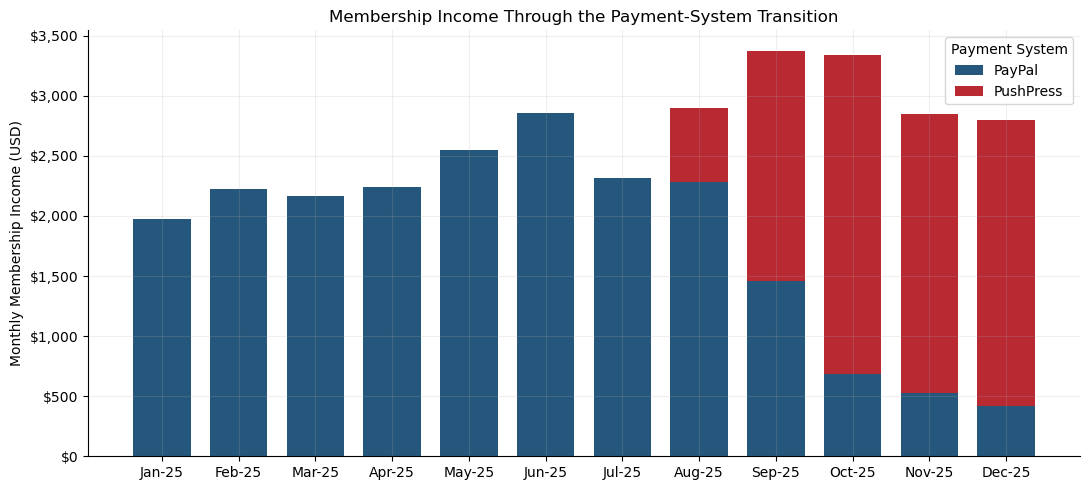

In [2]:
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(12)
ax.bar(x, income["PayPal"], color=BLUE, width=.75, label="PayPal")
ax.bar(x, income["PushPress"], bottom=income["PayPal"], color=RED,
       width=.75, label="PushPress")
ax.set(xticks=x, xticklabels=[x.strftime("%b-%y") for x in months],
       title="Membership Income Through the Payment-System Transition",
       ylabel="Monthly Membership Income (USD)", xlabel="", ylim=(0, None))
dollar_axis(ax)
ax.legend(title="Payment System")
show(ax)

## 2. Membership Plan Composition

Plan counts represent **estimated unique paying members per month**, after matching members across payment systems and preferring the new system for same-month duplicate payments. They are not a count of all members attending classes and should not be interpreted as verified attendance. Revenue-by-plan below uses the listed dues, not actual transaction settlements; it is therefore an illustrative mix rather than booked revenue.

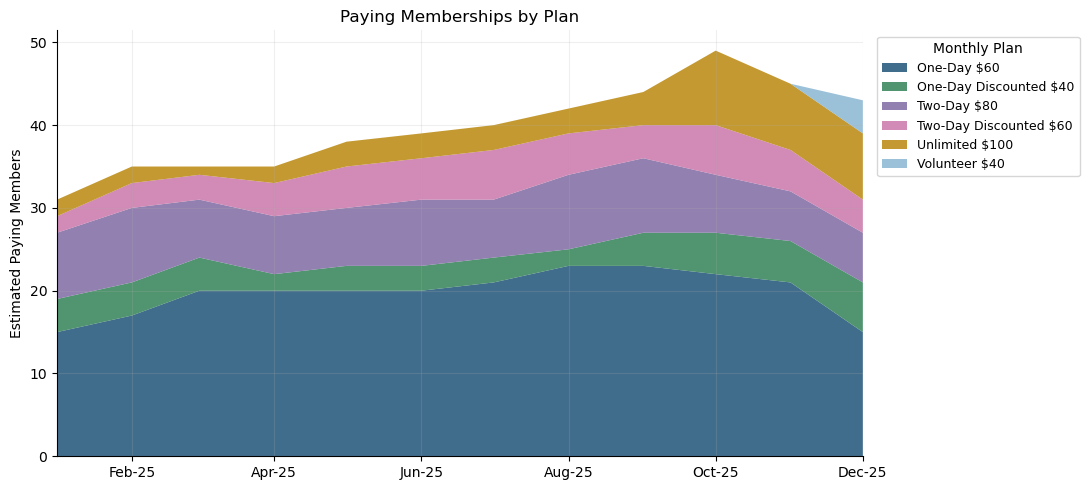

In [3]:
fig, ax = plt.subplots(figsize=(11, 5))
colors = [BLUE, GREEN, PURPLE, "#CC79AC", GOLD, LIGHT_BLUE]
ax.stackplot(months, *[counts[p].values for p in PLANS], labels=PLANS, colors=colors, alpha=.87)
ax.set(title="Paying Memberships by Plan", ylabel="Estimated Paying Members", xlabel="", ylim=(0, None), xlim=(months[0], months[-1]))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
ax.legend(title="Monthly Plan", loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
show(ax)

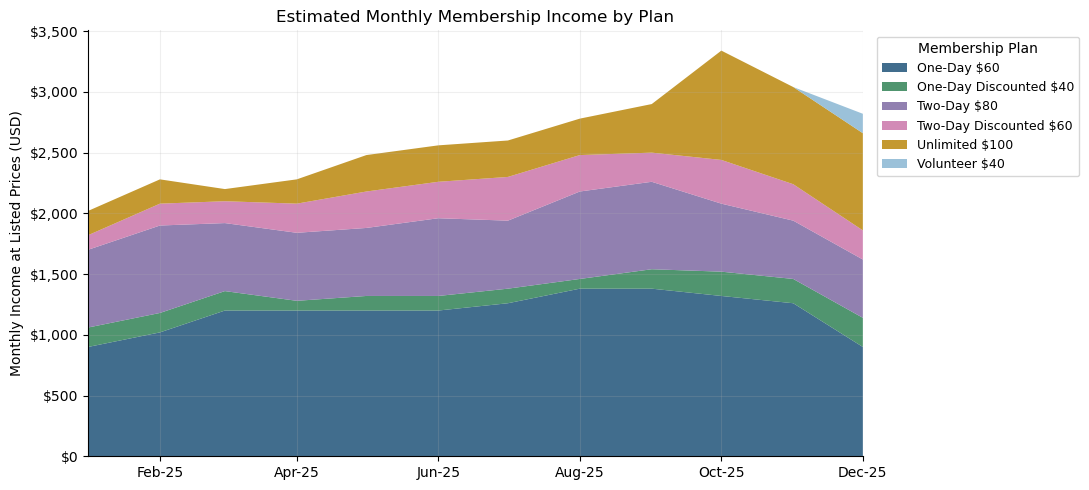

In [4]:
estimated_by_plan = counts.mul(PRICES, axis="columns")
fig, ax = plt.subplots(figsize=(11, 5))
ax.stackplot(months, *[estimated_by_plan[p].values for p in PLANS], labels=PLANS,
             colors=[BLUE, GREEN, PURPLE, "#CC79AC", GOLD, LIGHT_BLUE], alpha=.87)
ax.set(title="Estimated Monthly Membership Income by Plan", ylabel="Monthly Income at Listed Prices (USD)",
       xlabel="", ylim=(0, None), xlim=(months[0], months[-1]))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
dollar_axis(ax)
ax.legend(title="Membership Plan", loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
show(ax)

## 3. Break-Even Analysis

Identified monthly fixed obligations are compared with a broader estimate adding recurring supplies and maintenance. The weighted plan price uses October–December plan-count composition. These are **scenario thresholds**, not minimum legal or contractual membership requirements: unknown costs, free and discounted memberships, delayed payments, and changes in household demand can shift them.

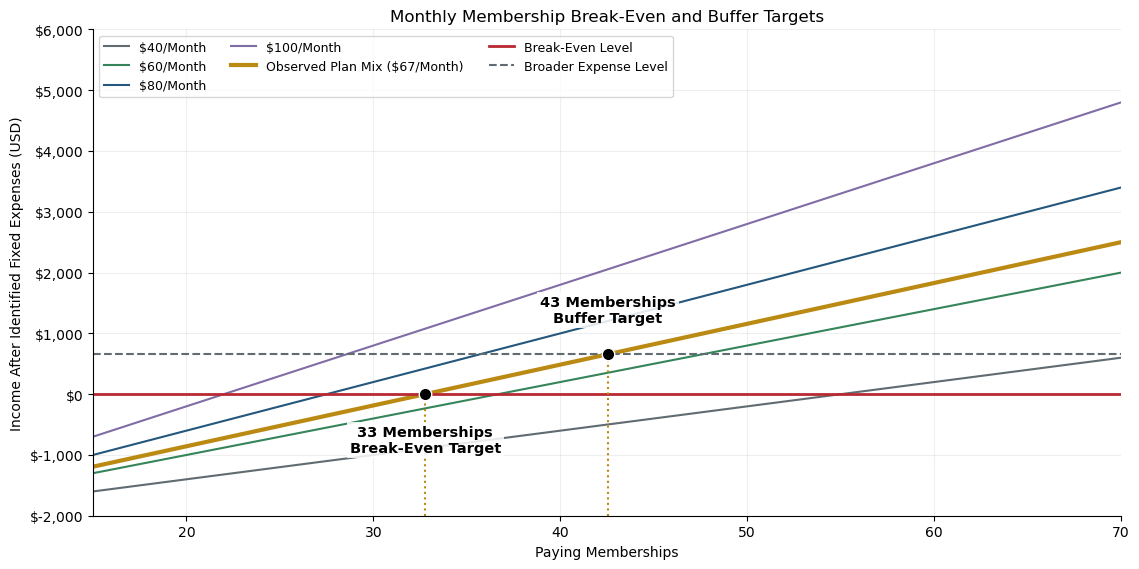

Weighted plan price: $67.15; fixed threshold: 33; broader threshold: 43.


In [5]:
recent = counts.loc["2025-10-01":"2025-12-01"].sum()
weighted_price = float((recent * PRICES).sum() / recent.sum())
needed_fixed = int(np.ceil(fixed / weighted_price))
needed_broader = int(np.ceil(broader / weighted_price))
exact_fixed = fixed / weighted_price
exact_broader = broader / weighted_price
xs = np.arange(15, 71)
fig, ax = plt.subplots(figsize=(11.5, 5.8))
for amount, color in [(40, GREY), (60, GREEN), (80, BLUE), (100, PURPLE)]:
    ax.plot(xs, xs * amount - fixed, color=color, label=f"${amount}/Month", lw=1.5)
ax.plot(xs, xs * weighted_price - fixed, color=GOLD, linewidth=3,
        label=f"Observed Plan Mix (${weighted_price:.0f}/Month)")
buffer_y = broader - fixed
ax.axhline(0, color=RED, linewidth=2, label="Break-Even Level")
ax.axhline(buffer_y, color=GREY, ls="--", label="Broader Expense Level")
box = dict(facecolor="white", edgecolor="none", alpha=.86, boxstyle="square,pad=.2")
for x, y in [(exact_fixed, 0), (exact_broader, buffer_y)]:
    ax.vlines(x, -2000, y, color=GOLD, linestyle=":", linewidth=1.5)
    ax.plot(x, y, "o", markersize=9, color="black", markeredgecolor="white", zorder=5)
ax.annotate(f"{needed_fixed} Memberships\nBreak-Even Target", (exact_fixed, 0), xytext=(0,-22),
            textcoords="offset points", ha="center", va="top", fontsize=10.5, fontweight="bold", bbox=box)
ax.annotate(f"{needed_broader} Memberships\nBuffer Target", (exact_broader,buffer_y), xytext=(0,21),
            textcoords="offset points", ha="center", va="bottom", fontsize=10.5, fontweight="bold", bbox=box)
ax.set(title="Monthly Membership Break-Even and Buffer Targets", xlabel="Paying Memberships",
       ylabel="Income After Identified Fixed Expenses (USD)", xlim=(15,70), ylim=(-2000,6000))
ax.legend(loc="upper left", fontsize=9, ncol=3)
dollar_axis(ax)
show(ax)
print(f"Weighted plan price: ${weighted_price:.2f}; fixed threshold: {needed_fixed}; broader threshold: {needed_broader}.")

## 4. Simple 2026 Scenario and Validation

A linear scenario extends the average monthly change over the July–December 2025 combined-income series. This is an illustrative projection, not a fitted growth guarantee. Two backtests predict September–December 2025 one month at a time using only earlier history: a last-month persistence forecast and a linear trend over observations available at that point. Mean absolute error (MAE) is reported for both. A wide downside-to-upside band shows judgmental scenarios, **not** statistical confidence bounds.

last_month MAE: $263/month
six_month_trend MAE: $402/month


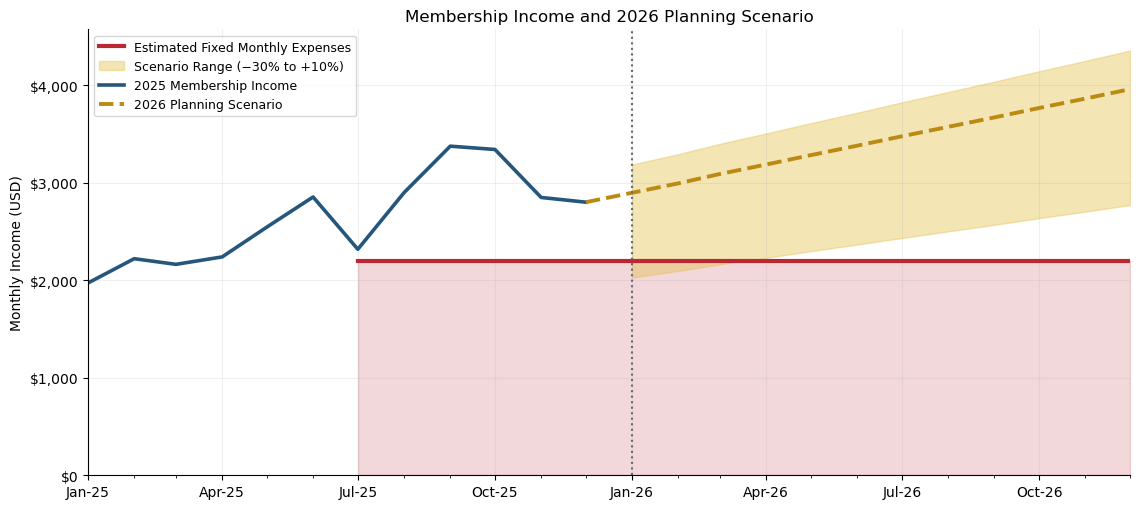

In [6]:
history = income["Total"].copy()
validation=[]
for t in range(8,12):
    past = history.iloc[:t]
    x = np.arange(len(past))
    slope, intercept = np.polyfit(x[-6:], past.values[-6:], 1)
    validation.append({"month":history.index[t], "actual":history.iloc[t],
                       "last_month":past.iloc[-1], "six_month_trend":intercept+slope*t})
validation = pd.DataFrame(validation)
for method in ["last_month", "six_month_trend"]:
    print(f"{method} MAE: ${np.abs(validation['actual']-validation[method]).mean():,.0f}/month")
# Scenarios are bounded below by zero; future observations are not available in this dataset.
change = float(history.loc["2025-07-01":"2025-12-01"].diff().dropna().mean())
forecast = pd.Series(np.maximum(0, history.iloc[-1] + change * np.arange(1,13)), index=future)
forecast_line = pd.concat([history.iloc[[-1]],forecast])
fig, ax = plt.subplots(figsize=(11.5, 5.2))
axis_dates = pd.date_range("2025-07-01", "2026-12-01", freq="MS")
ax.fill_between(axis_dates,0,fixed,color=RED,alpha=.18)
ax.plot(axis_dates,np.full(len(axis_dates),fixed),color=RED,linewidth=3,label="Estimated Fixed Monthly Expenses")
ax.fill_between(future,forecast*.70,forecast*1.10,color="#E5BE47",alpha=.4,
                label="Scenario Range (−30% to +10%)")
ax.plot(history.index,history,color=BLUE,lw=2.6,label="2025 Membership Income")
ax.plot(forecast_line.index,forecast_line,color=GOLD,ls="--",lw=2.8,label="2026 Planning Scenario")
ax.axvline(pd.Timestamp("2026-01-01"),color=GREY,linestyle=":")
ax.set(title="Membership Income and 2026 Planning Scenario", ylabel="Monthly Income (USD)",
       xlabel="",ylim=(0,None),xlim=(months[0],future[-1]))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1,4,7,10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
ax.xaxis.set_minor_locator(mdates.MonthLocator())
ax.legend(loc="upper left",fontsize=9)
dollar_axis(ax)
show(ax)

## 5. Operating Income, Event Contributions, and Cash Reserves

The monthly cash series distinguishes positive and negative movements after excluding identified transfers, PayPal authorization holds, and wallet funding. It is a classified *cash-flow proxy*, not a GAAP income statement. In particular, a ticketing payout already deposited through Stripe is not added again from the event summary. Annual Steel Jam ticket totals are reported alongside a broader event-related expense pool, without implying event-specific net profit.

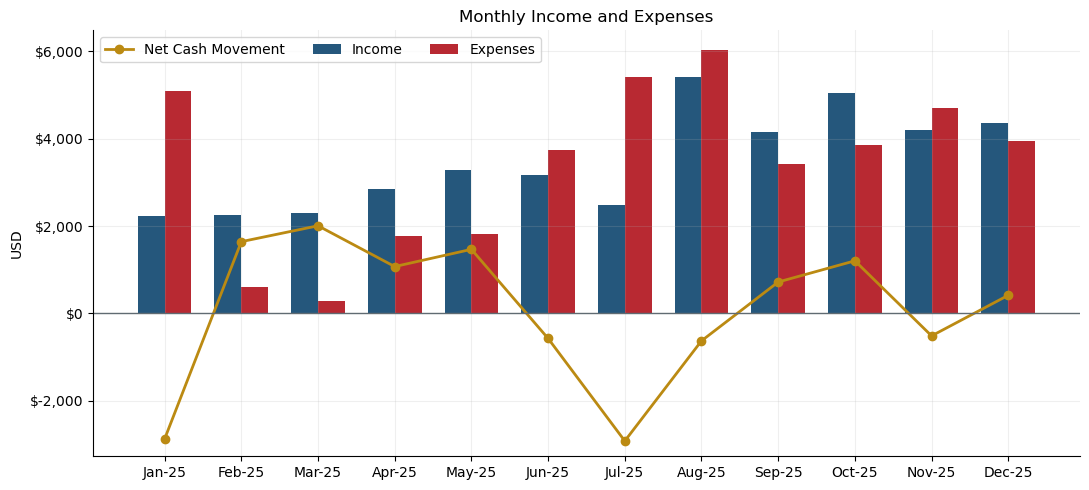

,Event,Ticket Sales (USD)
242,Steel Jam V,3071.59
243,Steel Jam VI,2319.50
244,Steel Jam VII,2997.25


Steel Jam V–VII ticket sales: $8,388.34
Identified annual event-cost pool: $7,988.25
Expenses are not consistently assignable to individual tournaments.
Estimated available year-end cash before restrictions: $10,769.04
Broader monthly expense coverage: 3.8 months
Six-month reserve target: $17,140.98


In [7]:
fig, ax = plt.subplots(figsize=(11,5))
x = np.arange(12); width=.35
ax.bar(x-width/2,cash["income"],color=BLUE,width=width,label="Income")
ax.bar(x+width/2,cash["expenses"],color=RED,width=width,label="Expenses")
ax.plot(x,cash["net"],color=GOLD,marker="o",linewidth=2,label="Net Cash Movement")
ax.axhline(0,color=GREY,linewidth=1)
ax.set(xticks=x,xticklabels=[m.strftime("%b-%y") for m in months],
       title="Monthly Income and Expenses",ylabel="USD",xlabel="",
       ylim=(min(0,cash['net'].min()*1.12),None))
ax.legend(ncol=3)
dollar_axis(ax)
show(ax)

sales = d.loc[d.section.eq("event_sales"),["category","amount"]].rename(columns={"category":"Event", "amount":"Ticket Sales (USD)"})
display(sales)
print(f"Steel Jam V–VII ticket sales: ${summary.loc['Annual Sales']:,.2f}")
print(f"Identified annual event-cost pool: ${summary.loc['Event Expense Pool']:,.2f}")
print("Expenses are not consistently assignable to individual tournaments.")
print(f"Estimated available year-end cash before restrictions: ${liquid:,.2f}")
print(f"Broader monthly expense coverage: {liquid/broader:.1f} months")
print(f"Six-month reserve target: ${6*broader:,.2f}")

## Assumptions, Limitations, and Recommendations

**Sources and preparation.** The private source records consisted of 2025 PayPal, Fairwinds and former LLC bank statements, PushPress paid transactions, and organizer-reviewed categorization. The published CSV was generated after amount/date standardization, review-category matching, exclusion of identified transfers and PayPal holds, and same-email monthly deduplication of identifiable membership plans. There is no personal-level information in the published dataset; private extraction and person matching cannot be reproduced from these aggregate records alone. Annual reserve totals combine accounts before any legal ownership or spending restriction assessment.

**Interpretation.** The 2025 payment platform transition complicates a direct comparison of gross platform sales with net PayPal settlements. The available membership counts are not complete attendance records. The linear projection is a scenario rather than a validated 2026 outcome. Event expenses cannot be reliably matched to particular Steel Jam events, and the cash classification is not a financial-statement reconciliation.

**Recommendations.** (1) Track monthly paid plan counts and revenue on a unified schedule, including refunds. (2) Review the mix-adjusted threshold of approximately 33 paying memberships for fixed costs and 43 for broader recurring expenses, revising assumptions quarterly. (3) Adopt a board-approved unrestricted-reserve policy and establish separate equipment and facility budgets. (4) Track direct income and expense codes for individual events. (5) Improve class check-in quality before evaluating per-class billing or reservation policies. Avoid pricing changes that unnecessarily restrict access to HEMA training.

**Ethical controls.** Only aggregated financial and membership data are published. This protects member and donor identities while letting readers reproduce the reported charts. Small-group plan counts and organizational financial figures should still be cleared for public release by the board. Source-record reconciliation remains private.

**Public reproduction.** With `pandas`, `numpy`, and `matplotlib` installed, place the CSV beside the notebook and choose **Restart Kernel and Run All Cells**. This notebook reproduces all reported visuals and post-aggregation modeling, not private transaction-level extraction.